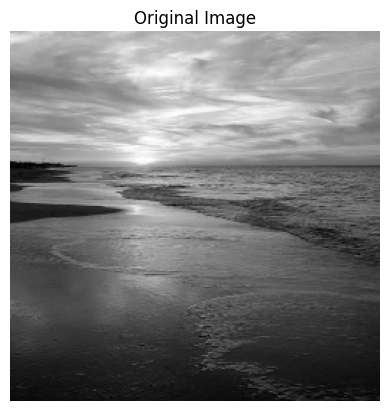

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("img2.jpeg", cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError("img2.jpeg not found")

image = cv2.resize(image, (256, 256))
image = image.astype(np.float32) / 255.0

plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

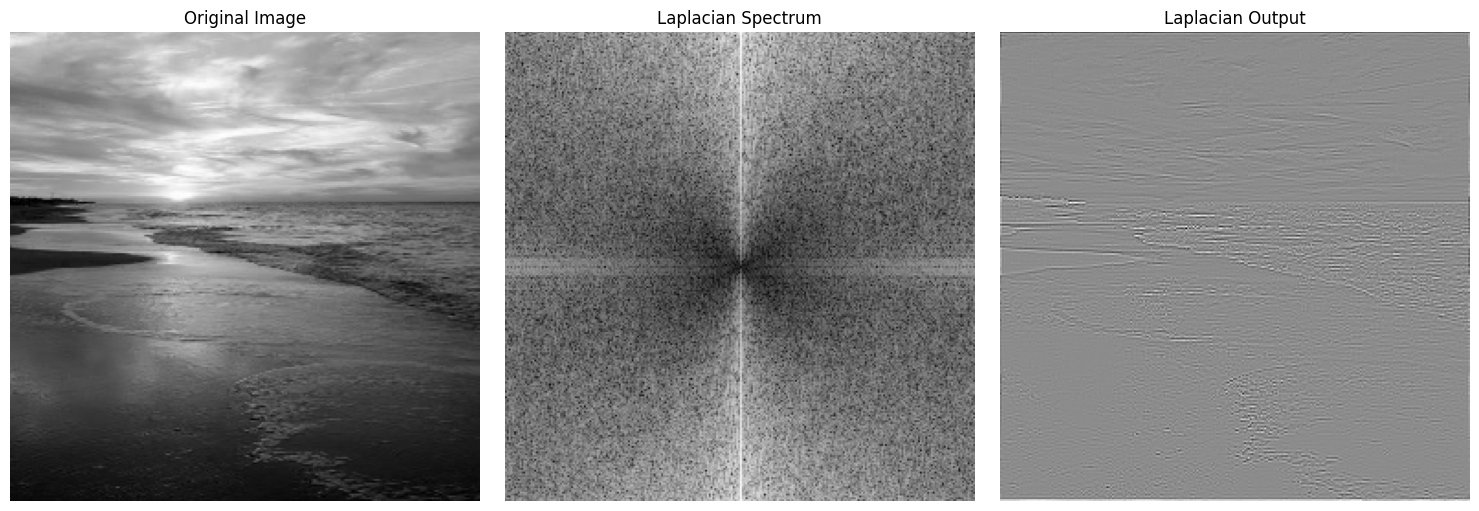

In [10]:
M, N = image.shape

u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

F = np.fft.fft2(image)
F_lap = F * laplacian_filter
laplacian_image = np.fft.ifft2(F_lap).real

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(np.log1p(np.abs(np.fft.fftshift(F_lap))), cmap="gray")
plt.title("Laplacian Spectrum")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap="gray")
plt.title("Laplacian Output")
plt.axis("off")

plt.tight_layout()
plt.show()

The Laplacian filter highlights edges and fine details by emphasizing high frequencies.

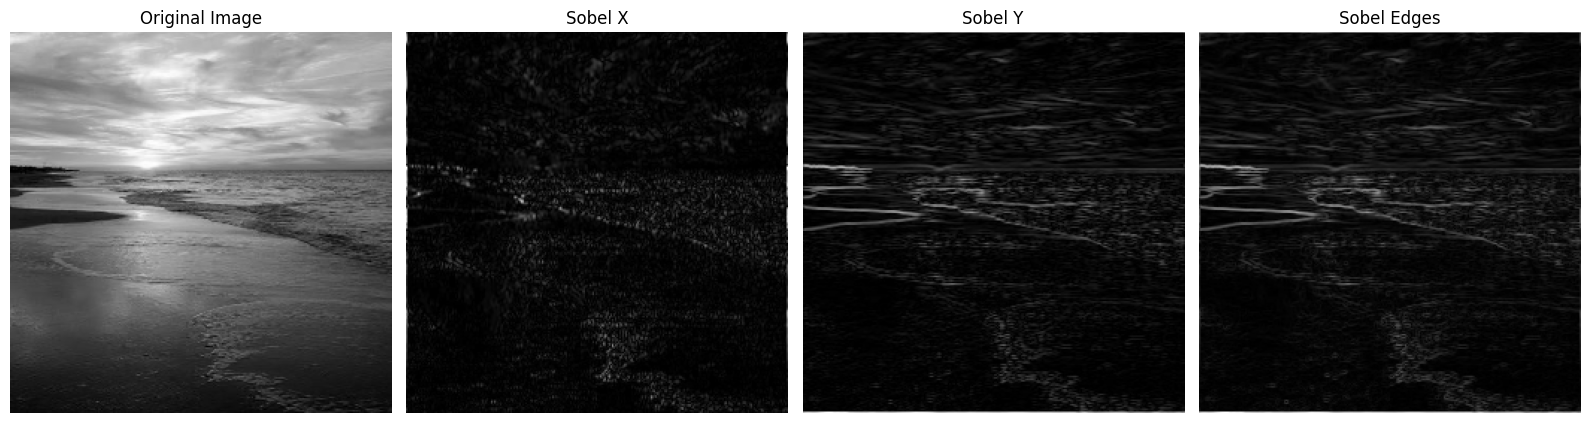

In [11]:
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

sobel_y = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
], dtype=np.float32)

def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape, dtype=np.float32)
    kh, kw = kernel.shape
    cy, cx = shape[0] // 2, shape[1] // 2
    padded[cy-kh//2:cy+kh//2+1, cx-kw//2:cx+kw//2+1] = kernel
    return np.fft.fft2(np.fft.ifftshift(padded))

F = np.fft.fft2(image)

H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

G_x = np.fft.ifft2(F * H_x).real
G_y = np.fft.ifft2(F * H_y).real

sobel_magnitude = np.sqrt(G_x**2 + G_y**2)
sobel_magnitude = sobel_magnitude / (sobel_magnitude.max() + 1e-8)

plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(np.abs(G_x), cmap="gray")
plt.title("Sobel X")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(np.abs(G_y), cmap="gray")
plt.title("Sobel Y")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(sobel_magnitude, cmap="gray")
plt.title("Sobel Edges")
plt.axis("off")

plt.tight_layout()
plt.show()

The Sobel filter detects edges in horizontal and vertical directions. Combining both results gives a clearer edge map.